# Options Pricing: Black-Scholes and the Greeks from First Principles
**Author:** Silam Shrestha

**What is an option?** A **call** gives the right to *buy* a stock at a fixed price (the **strike**, K) on a future date. A **put** gives the right to *sell*.

**Black-Scholes** gives a fair price using 5 inputs: stock price S, strike K, time to expiry T (years), interest rate r, volatility σ.

We will: build the formula, check it three independent ways, compute the Greeks, find implied volatility, and question the assumptions.

## Step 1. Tools

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

## Step 2. The Black-Scholes formula

d1 = [ln(S/K) + (r + σ²/2)·T] ÷ (σ·√T), and d2 = d1 − σ·√T

**Call** = S·N(d1) − K·e^(−rT)·N(d2)  **Put** = K·e^(−rT)·N(−d2) − S·N(−d1)

N(·) is the standard normal cumulative probability.

In [2]:
def d1_d2(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return d1, d1 - sigma * np.sqrt(T)

def bs_price(S, K, T, r, sigma, kind="call"):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    if kind == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

S, K, T, r, sigma = 100, 100, 1.0, 0.01, 0.20
call, put = bs_price(S, K, T, r, sigma, "call"), bs_price(S, K, T, r, sigma, "put")
print(f"Call = {call:.4f}, Put = {put:.4f}")

Call = 8.4333, Put = 7.4383


## Step 3. Check 1: put-call parity
A model-free rule: **Call − Put = S − K·e^(−rT)**. If our code is right, both sides match.

In [3]:
print("Call - Put       =", round(call - put, 6))
print("S - K*exp(-rT)   =", round(S - K * np.exp(-r * T), 6))

Call - Put       = 0.995017
S - K*exp(-rT)   = 0.995017


## Step 4. Check 2: Monte Carlo simulation
Simulate many possible future stock prices, average the payoff, and discount it. With enough simulations it should match Black-Scholes.

In [4]:
rng = np.random.default_rng(42)
n = 500_000
Z = rng.standard_normal(n)
ST = S * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
payoff = np.maximum(ST - K, 0)
mc = np.exp(-r * T) * payoff.mean()
se = np.exp(-r * T) * payoff.std() / np.sqrt(n)
print(f"Monte Carlo call = {mc:.4f} +/- {1.96*se:.4f} (95% interval); Black-Scholes = {call:.4f}")

Monte Carlo call = 8.4351 +/- 0.0374 (95% interval); Black-Scholes = 8.4333


## Step 5. The Greeks: how the price reacts
| Greek | Meaning |
|---|---|
| Delta | Price change when the stock moves 1 |
| Gamma | How fast Delta changes |
| Vega | Price change when volatility rises 1 point (1.00 = 100%) |
| Theta | Price change per year as time passes |
| Rho | Price change when interest rates rise 1 point |

In [5]:
def greeks(S, K, T, r, sigma, kind="call"):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    pdf = norm.pdf(d1)
    gamma = pdf / (S * sigma * np.sqrt(T))
    vega = S * pdf * np.sqrt(T)
    if kind == "call":
        delta = norm.cdf(d1)
        theta = -S * pdf * sigma / (2 * np.sqrt(T)) - r * K * np.exp(-r * T) * norm.cdf(d2)
        rho = K * T * np.exp(-r * T) * norm.cdf(d2)
    else:
        delta = norm.cdf(d1) - 1
        theta = -S * pdf * sigma / (2 * np.sqrt(T)) + r * K * np.exp(-r * T) * norm.cdf(-d2)
        rho = -K * T * np.exp(-r * T) * norm.cdf(-d2)
    return pd.Series({"Delta": delta, "Gamma": gamma, "Vega": vega, "Theta": theta, "Rho": rho})

pd.DataFrame({"Call": greeks(S, K, T, r, sigma, "call"), "Put": greeks(S, K, T, r, sigma, "put")})

,Call,Put
Delta,0.559618,-0.440382
Gamma,0.019724,0.019724
Vega,39.447933,39.447933
Theta,-4.420078,-3.430028
Rho,47.528451,-51.476533


## Step 6. Check 3: Greeks by finite differences
Nudge each input a tiny amount and see how the price moves. It should match the formulas above.

In [6]:
h = 1e-4
num = pd.Series({
    "Delta": (bs_price(S+h, K, T, r, sigma) - bs_price(S-h, K, T, r, sigma)) / (2*h),
    "Gamma": (bs_price(S+h, K, T, r, sigma) - 2*call + bs_price(S-h, K, T, r, sigma)) / h**2,
    "Vega":  (bs_price(S, K, T, r, sigma+h) - bs_price(S, K, T, r, sigma-h)) / (2*h),
    "Theta": -(bs_price(S, K, T+h, r, sigma) - bs_price(S, K, T-h, r, sigma)) / (2*h),
    "Rho":   (bs_price(S, K, T, r+h, sigma) - bs_price(S, K, T, r-h, sigma)) / (2*h),
})
pd.DataFrame({"Formula": greeks(S, K, T, r, sigma), "Numerical": num})

,Formula,Numerical
Delta,0.559618,0.559618
Gamma,0.019724,0.019724
Vega,39.447933,39.447933
Theta,-4.420078,-4.420078
Rho,47.528451,47.528450


## Step 7. Visualise how price and Delta change with the stock price

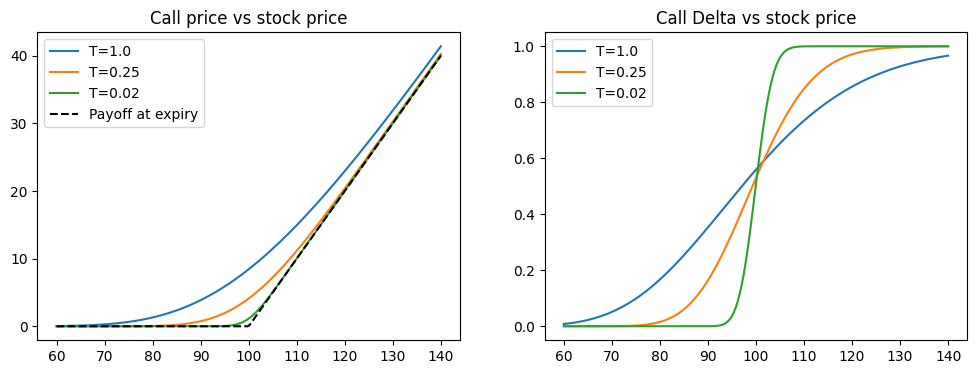

In [7]:
grid = np.linspace(60, 140, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for t in [1.0, 0.25, 0.02]:
    ax[0].plot(grid, bs_price(grid, K, t, r, sigma), label=f"T={t}")
    ax[1].plot(grid, greeks(grid, K, t, r, sigma)["Delta"], label=f"T={t}")
ax[0].plot(grid, np.maximum(grid - K, 0), "k--", label="Payoff at expiry")
ax[0].set_title("Call price vs stock price"); ax[1].set_title("Call Delta vs stock price")
for a in ax: a.legend()
plt.show()

## Step 8. Implied volatility
In real markets we **see the option price** and solve backwards for σ. That σ is the **implied volatility**, the market's view of future volatility.

In [8]:
def implied_vol(price, S, K, T, r, kind="call"):
    return brentq(lambda s: bs_price(S, K, T, r, s, kind) - price, 1e-4, 5.0)

for market_price in [5.0, 8.43, 12.0]:
    print(f"Option price {market_price:>5} -> implied vol {implied_vol(market_price, S, K, T, r):.2%}")

Option price   5.0 -> implied vol 11.30%
Option price  8.43 -> implied vol 19.99%
Option price  12.0 -> implied vol 29.06%


## Step 9. Assumptions: where Black-Scholes is wrong
| Assumption | Reality |
|---|---|
| Volatility is constant | Volatility changes; implied vol differs by strike (**volatility smile/skew**) |
| Returns are normal | Real returns have **fat tails** (crashes are more common) |
| Continuous trading, no costs | Trading is discrete and costs money |
| Constant interest rate, no dividends | Rates change; dividends lower call prices |
| European exercise only | Many stock options are American (can exercise early) |

## Conclusions
- **All three independent checks agree with the formula.** Put-call parity matches to 6 decimals (0.995017 on both sides). Monte Carlo with 500,000 paths gives 8.4351 ± 0.0374 vs Black-Scholes 8.4333. Finite-difference Greeks match the analytical Greeks to at least 6 decimals.
- **Implied volatility inversion works:** a price of 8.43 recovers σ ≈ 19.99%, close to the 20% used to price it.
- **The assumption that matters most in practice is constant volatility.** Real implied volatility differs by strike and maturity (the smile and skew), so one σ misprices out-of-the-money options, especially downside puts, where fat-tailed crash risk is priced in.